In [1]:
# Origin: https://github.com/suinleelab/MONET

In [2]:
import sys
import os
import packaging
# Adds the 'src' directory to the path so you can import its subfolders directly
sys.path.append(os.path.abspath("src"))
sys.path.append(os.path.abspath("scripts"))
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

In [3]:
# original https://github.com/mlfoundations/open_clip (not for this code)

from src import clip
import torchvision.transforms as T
from PIL import Image
import torch
from torch import nn
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from transformers import AutoProcessor, AutoModelForZeroShotImageClassification

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
constants_zoo = {
    'imagenet': {'mean': (0.485, 0.456, 0.406), 'std': (0.228, 0.224, 0.225)},
    'openai_clip':{'mean': (0.48145466, 0.4578275, 0.40821073), 'std': (0.26862954, 0.26130258, 0.27577711)},
    'uniform': {'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5)}
}
constants = constants_zoo['openai_clip']

mean, std = constants.get('mean'), constants.get('std')
dl_preprocess = transforms.Compose([
    transforms.Normalize(mean=mean, 
                         std=std),
])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [1]:
!nvidia-smi

Fri Oct 23 12:20:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H100 PCIe               On  |   00000000:B5:00.0 Off |                    0 |
| N/A   55C    P0            101W /  350W |   69445MiB /  81559MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [8]:
##% https://github.com/suinleelab/MONET
print("Original Monet Model")

device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = clip.load("ViT-L/14", jit=False)[0]
model.load_state_dict(torch.hub.load_state_dict_from_url("https://aimslab.cs.washington.edu/MONET/weight_clip.pt", map_location= device))
model.eval()
print("model was loaded using original clip implementation")
    

Original Monet Model


RuntimeError: CUDA error: CUDA-capable device(s) is/are busy or unavailable
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [6]:
##% custom model loading# getting the fine tuned model
print("Custom Monet Model")
import scripts.custom_models.monet_custom_classifer
import importlib
from geom_hyp import lorentz as L
from geom_hyp import manifold_conversion as MC
importlib.reload(scripts.custom_models.monet_custom_classifer)
from scripts.custom_models.monet_custom_classifer import MonetWithHead, MonetWithHypHead

Custom Monet Model


In [7]:
model = MonetWithHead(num_classes= 10)

In [7]:
ls ../../../../../projects/academic/sangst/zahidhas/Model_Weights/Monet/

Monet_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer.pth
Monet_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_noCE.pth
Monet_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius.pth
Monet_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_2.pth
Monet_hyper_sarkar_head_64_ISIC2019_weight_ce_multilayer.pth
Monet_hyper_sarkar_head_64_ISIC2019_weight_ce_multilayer_noCE.pth
Monet_hyper_sarkar_head_64_ISIC2019_weight_ce_multilayer_small_radius.pth


In [7]:
# model manual checking 
print("hyperbolic head model")
results = torch.load("../Datasets/sarker_embeddingDerm12345 datasets_64_small_radius.pt")
z_p = results["data"]  # torch.Tensor
z_l = MC.poincare_to_lorentz(z_p) # lorentz points
# data loader 
# scaling 
mul_factor = 2.0
z_l = L.exp_map0(L.log_map0(z_l[:, 1:]) * mul_factor)

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MonetWithHypHead(64, l_target= z_l[0:40,:].to(device), multilayer= True) # lorentz space components

# model = DermLIPWithHead(11) # Euclidean model

# Weight loading
PATH = '../../../../../projects/academic/sangst/zahidhas/Model_Weights/Monet/Monet_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_2.pth'

checkpoint = torch.load(PATH, map_location=device)
missing, unexpected = model.load_state_dict(checkpoint['model_state_dict'],  strict=False)
print(f"Missing: {missing}")
print(f"Unexpected: {unexpected}")

hyperbolic head model


/scratch/26547344/ipykernel_704631/1030967168.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  results = torch.load("../Datasets/sarker_embeddingDerm12345 datasets_64_sma

Missing: []
Unexpected: []


In [ ]:
import clip
tokenized_text = clip.tokenize('garbage').to(device)
model.encode_text(tokenized_text)

In [37]:
# Load model using huggingface clip implementation
# processor_hf = AutoProcessor.from_pretrained("chanwkim/monet")
# model_hf = AutoModelForZeroShotImageClassification.from_pretrained("chanwkim/monet")
# model_hf.to(device)
# model_hf.eval()
# print("model was loaded using huggingface clip implementation")    
# print("identical to earlier model, will not use it")
# model_hf.vision_model.embeddings.patch_embedding.weight - model.visual.conv1.weight

In [8]:
# data loading. 

import sys, importlib
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

import Datasets.MILK_10K.Milk10_dataset_loader 
import Datasets.isic_kaggle_2016.IsicKaggle2016
import Datasets.fitzpatrick17k.fitzpatrick_data_loader

importlib.reload(Datasets.MILK_10K.Milk10_dataset_loader)

from Datasets.MILK_10K.Milk10_dataset_loader import MILK10kDataset, get_image_transform
from Datasets.isic_kaggle_2016.IsicKaggle2016 import TumorDataset
from Datasets.fitzpatrick17k.fitzpatrick_data_loader import Fitz17kDataset

# Derm12345 loading

path_to_root = os.path.abspath(os.path.join('../../../../../projects/academic/sangst/zahidhas/Datasets'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

from DERM12345.derm12345_data_loader import DERM12345Dataset


# ISIC loading
from isic_2019.isic_2016_dataset_loader import ISIC2019Dataset


In [9]:
im_size = 224

transform_train_no_np = transforms.Compose([
    transforms.Resize((im_size, im_size),  interpolation=InterpolationMode.BICUBIC),  # Resize the image
    transforms.PILToTensor()  # Convert to uint8 tensor array [c, h, w]
])

In [10]:
# ISIC 2019 datasets
root = "../../../../../projects/academic/sangst/zahidhas/Datasets/isic_2019"

dataset_keep_track = "Isic2019 datasets"

img_size = 224

train_dataset = ISIC2019Dataset(
    root=root,
    split="test",
    image_transform=get_image_transform('train', img_size=img_size),
    balanced=False,
    seed=44,
)

In [47]:
# Derm12345 dataset
dataset_keep_track = "Derm12345 datasets"
print(dataset_keep_track)

root             = "../../../../../projects/academic/sangst/zahidhas/Datasets/DERM12345/"

img_size = 224

train_dataset  = DERM12345Dataset(
        root=root,
        split="test",
        image_transform=get_image_transform("train", img_size = img_size),
        target_col="label",
        balanced=False,
        seed=44,
    )

Derm12345 datasets


In [ ]:
# MILK 10K dataset
dataset_keep_track = "MILK 10K datasets"
print(dataset_keep_track)

root             = '../Datasets/MILK_10K/Train'
split            = 'train'

train_dataset =  MILK10kDataset(
        root             = root, 
        split            = split,
        image_transform  = get_image_transform(split, im_size),
        balanced         = False,
        seed             = 44,
    )

In [11]:
# common path begins HERE
print(dataset_keep_track)
im, label = train_dataset[0]

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,persistent_workers=False,
)

Isic2019 datasets


In [12]:
#%% iteration over the dataset
print(dataset_keep_track)

loader_iter = iter(train_loader)
images, labels = next(loader_iter)

if dataset_keep_track == "MILK 10K datasets":
    type_image = images['dermoscopic']
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)
elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
    type_image = images
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)
    

Isic2019 datasets
Isic2019 datasets


In [14]:
len(train_loader)

156

In [17]:
# panderm vision transformer model.
# forward code: https://github.com/suinleelab/MONET/blob/main/src/clip/model.py
import torch.nn.functional as F
print("check if the model is in float, else convert it")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = model.to(device)
model.eval()

print(dataset_keep_track)
print("CLIP VIT ONLY")

# necessary funciton
def _expand_token(token, batch_size: int):
    return token.view(1, 1, -1).expand(batch_size, -1, -1)


for _ in range(1):

    images, labels = next(loader_iter)

    if dataset_keep_track == "MILK 10K datasets":
        type_image = images['dermoscopic']
    elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
        type_image = images

    
    input_image = dl_preprocess(type_image/255.0)
    input_image = input_image.to(device)
    

    with torch.no_grad():
        input_image = input_image.to(device)#.half()
        
        o = model.visual(input_image)

        oupt_list, labs1 = [], []
        labs2 = []
        oupt_list.append(o.cpu())
        # labs1.append(labels['metadata']['dermoscopic_image_type'])
        labs2.append(labels['class_index'])


    with torch.no_grad():
        input_image = input_image.to(device)#.half()
    
        o = model.visual(input_image)
        
        x = model.visual.conv1(input_image)  # shape = [*, width, grid, grid]
        x = x.reshape(x.shape[0], x.shape[1], -1)  # shape = [*, width, grid ** 2]
        x = x.permute(0, 2, 1)  # shape = [*, grid ** 2, width]
        x = torch.cat(
            [
                model.visual.class_embedding.to(x.dtype)
                + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device),
                x,
            ],
            dim=1,
        )  # shape = [*, grid ** 2 + 1, width]
        x = x + model.visual.positional_embedding.to(x.dtype)
        x = model.visual.ln_pre(x)
    
        x = x.permute(1, 0, 2)  # NLD -> LND
        x1 = model.visual.transformer(x) # need to get inside this
        
        for r in model.visual.transformer.resblocks[0:-1]: # loop identical to # x = model.visual.transformer(x)
            x = r(x)
        r = model.visual.transformer.resblocks[-1] # getting into the last layer    
        full_atten =  r.attn( r.ln_1(x), r.ln_1(x), r.ln_1(x), need_weights=True, average_attn_weights=False)
        x = x + full_atten[0]
        x = x + r.mlp(r.ln_2(x))
        x = x.permute(1, 0, 2)  # LND -> NLD
        attn = full_atten[1]

check if the model is in float, else convert it
Using device: cuda
Isic2019 datasets
CLIP VIT ONLY


In [52]:
try: 
    flat_labels = torch.cat(labs2, dim = 0)
except:
    flat_labels = [label for batch in labs2 for label in batch]

oupt = torch.cat(oupt_list, dim = 0)

len(flat_labels)
# one_hot_labels = F.one_hot(flat_labels.long(), num_classes= 11)

1296

In [53]:
#further 
print("Hyperbolic head model")
from geom_hyp import lorentz as L

mul_factor = 3.0

def clip_safe(input_vector, r):
    norms = torch.norm(input_vector, dim=-1, keepdim=True).clamp(min=1e-8)
    return input_vector * (float(r) / norms).clamp(max=1)

with torch.no_grad():
    image_feats = model.clf_head(oupt.to(device)) # projection head

    image_feats = image_feats * model.visual_alpha.exp() * mul_factor
    # clipping hyperbolic tangent vector
    image_feats = clip_safe(image_feats, model.clip_value) 
    # exponential mapping
    with torch.autocast(model.device.type, dtype=torch.float32):
        image_feats_h = L.exp_map0(image_feats, model.curv.exp())

    # _a, _d, _ah = L.oxy_angle_dist(image_feats_h, model.l_target, flat_labels, min_radius= 0.1)

Hyperbolic head model


In [54]:
with torch.no_grad():
    _a, _d, _ah = L.oxy_dist_angle_no_label(image_feats_h.to(device), model.l_target, min_radius= 0.1)

    image_logits = - _d * 5
    angle_min = _a.min(dim = -1) # return values and indices
    
    dist_min = (-_d).min(dim = -1) # return values and indices


# _d.shape
# labels_idx = flat_labels.long()
# selected_scores = _d[torch.arange(_d.size(0), device=_d.device), labels_idx]
# selected_scores = _d.min(dim = -1)

In [55]:
ignore_classes = torch.tensor([-100], device=flat_labels.device)
keep = ~torch.isin(flat_labels, ignore_classes)

/user/zahidhas/FM_Skin_Cancer/SkinFM_med/utils_external/plot_helper_visual.py:91: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


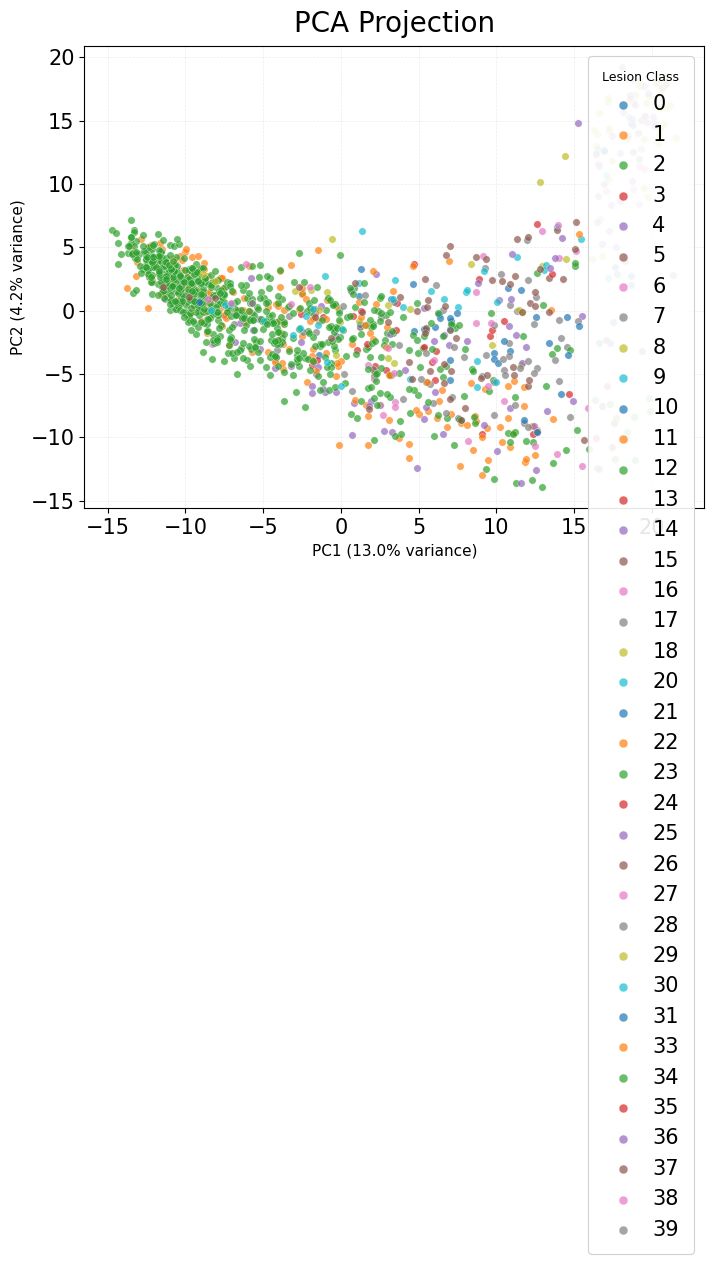

In [56]:
# [flat_labels[i] for i in clusters[1]]
import utils_external.plot_helper_visual as plot_helper_visual 
importlib.reload(plot_helper_visual)# Reload 
plot_pca_clusters = plot_helper_visual.plot_pca_clusters


import numpy as np
plot_pca_clusters (oupt[keep], flat_labels[keep], name = None)

# labels['class_vector'].shape

In [57]:
import utils_external.classification_metrics as accuracy_mat
importlib.reload(accuracy_mat)
multiclass_metrics = accuracy_mat.multiclass_metrics
correct_wrong_indices = accuracy_mat.correct_wrong_indices
import utils_external.hierarchy_matrics as hierarchy 
importlib.reload(hierarchy)# Reload 
hierarchical_metrics = hierarchy.hierarchical_metrics # Extract the updated function from the reloaded module

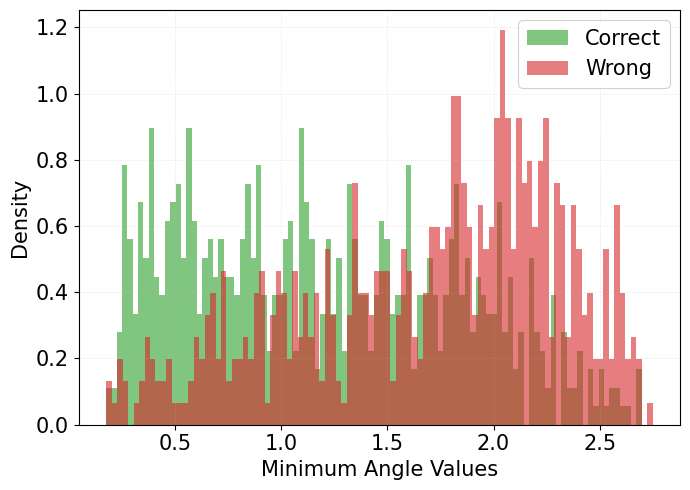

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

cls_wrong = correct_wrong_indices(image_logits[keep], flat_labels[keep])
wrong_idx = cls_wrong["wrong_sample_indices"].to(oupt.device)
correct_idx = cls_wrong["correct_sample_indices"].to(oupt.device)

wrong_length = angle_min.values[keep][wrong_idx]#.norm(dim=-1)
correct_length = angle_min.values[keep][correct_idx]#.norm(dim=-1)

# wrong_length = oupt[keep][wrong_idx].norm(dim=-1)
# correct_length = oupt[keep][correct_idx].norm(dim=-1)


# wrong_length = oupt[0:960].norm(dim=-1)
# correct_length = oupt[960:].norm(dim=-1)

wrong_values = wrong_length.detach().cpu().numpy()
correct_values = correct_length.detach().cpu().numpy()


plot_norm_dist(correct_values, wrong_values, None)

Direction       : x1 <= threshold
AUROC           : 0.7124
Best threshold  : 1.677923
TPR             : 0.7334
FPR             : 0.4020
Youden's J      : 0.3314


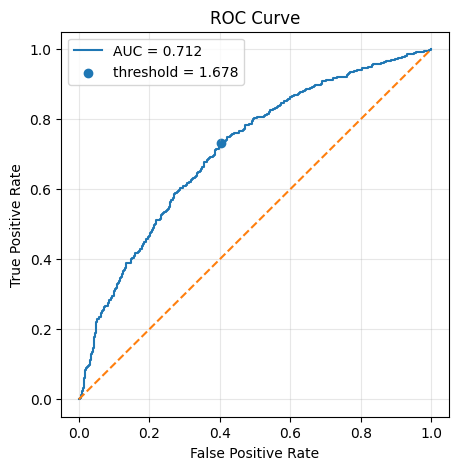

{'auc': 0.7123861378287917,
 'threshold': 1.6779234,
 'direction': 'x1 <= threshold',
 'tpr': 0.7334273624823695,
 'fpr': 0.4020442930153322,
 'youden_j': 0.33138306946703733}

In [61]:
from utils_external.classification_metrics import roc_separation
roc_separation(correct_length, wrong_length)

In [59]:
def plot_norm_dist(correct, wrong, name="feature_norm_distribution.svg", bins=100):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(correct, bins=bins, density=True, alpha=0.6, color="tab:green", label="Correct")
    ax.hist(wrong, bins=bins, density=True, alpha=0.6, color="tab:red", label="Wrong")
    ax.set_xlabel(r"Minimum Angle Values", fontsize=15)
    ax.set_ylabel("Density", fontsize=15)
    leg = ax.legend(loc="upper right", fontsize=15, frameon=True, framealpha=0.9)
    leg.get_frame().set_linewidth(0.8)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.25)
    ax.tick_params(axis="both", labelsize=15)
    plt.tight_layout()
    if name is not None:
        plt.savefig(name, format="svg", bbox_inches="tight")
    plt.show()

In [64]:
result = multiclass_metrics(image_logits[keep], flat_labels[keep],  topk = [5])
result

{'accuracy': 0.5470679012345679,
 'balanced_accuracy': 0.233366713638163,
 'macro_f1': 0.2104606541620276,
 'weighted_f1': 0.48988497460033864,
 'classwise_f1': tensor([0.0000, 0.0000, 0.5682, 0.0874, 0.0000, 0.0000, 0.6667, 0.3810, 0.5306,
         0.0000, 0.6190, 0.4133, 0.4000, 0.0000, 0.0762, 0.0000, 0.4602, 0.4230,
         0.1185, 0.0000, 0.7879, 0.0000, 0.1499, 0.7386, 0.0000, 0.5000, 0.0000,
         0.1667, 0.1000, 0.0000, 0.0196, 0.3472, 0.0000, 0.0000, 0.0000, 0.0000,
         0.2373, 0.3214, 0.0952, 0.0000], dtype=torch.float64),
 'classwise_precision': tensor([0.0000, 0.0000, 0.5319, 0.2273, 0.0000, 0.0000, 1.0000, 0.6667, 0.4727,
         0.0000, 0.5909, 0.4615, 0.4286, 0.0000, 0.2667, 0.0000, 0.4091, 0.5610,
         0.2667, 0.0000, 0.8667, 0.0000, 0.2687, 0.6828, 0.0000, 1.0000, 0.0000,
         0.3333, 0.2000, 0.0000, 0.1667, 0.6250, 0.0000, 0.0000, 0.0000, 0.0000,
         0.3235, 0.5000, 0.3333, 0.0000], dtype=torch.float64),
 'classwise_recall': tensor([0.0000, 0.00

In [28]:
from Datasets.label_details import get_hierarchy
TREE, NODES, _= get_hierarchy("derm12345") # milk10k, isic2019, derm12345

In [29]:
topk=2
h_metrics = hierarchical_metrics(
    output=image_logits[keep],       # [N, number_of_leaves]
    labels=flat_labels[keep],  # [N]
    tree=TREE,
    nodes=NODES,
    topk= topk,)

print('Mistake Severity ', h_metrics["mistake_severity"])
print('Hierarchical Severity ', h_metrics["hierarchical_distance_top_" + str(topk)])
print(h_metrics["accuracy_at_depth"]) # h_metrics.keys()

Mistake Severity  2.0641891956329346
Hierarchical Severity  1.0553836822509766
{0: 1.0, 1: 0.9306930303573608, 2: 0.6794554591178894, 3: 0.6336633563041687}


In [79]:
attn[:, :, 0, 1:].shape

torch.Size([8, 16, 256])

In [18]:
cls_attn = attn[:, :, 0, 1:]   # [B, 12, 196]
cls_attn = cls_attn.mean(dim=1)
# cls_attn = cls_attn[0]
# cls_attn = cls_attn[:,4,:]
B = cls_attn.shape[0]
mask = cls_attn.reshape(B, 16, 16)

In [21]:
# image points connection 
image_feats = torch.tensor(x[:, 1:, :], dtype = torch.float32) # bs, no_feats (196), feat_dim 

def cosine_affinity(features: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Args:    features: [B, N, D]
    Returns: affinity: [B, N, N]
    """
    features = F.normalize(features, p=2, dim=-1, eps=eps)
    # [B, N, D] @ [B, D, N] -> [B, N, N]
    affinity = torch.bmm(features, features.transpose(1, 2))
    affinity = (affinity+ 1)/2
    return affinity

def exponential_affinity(
    features: torch.Tensor, temperature: float = 1.0,
    eps: float = 1e-6) -> torch.Tensor:
    """
    Args:        features: [B, N, D]
    Returns:        affinity: [B, N, N]
    """
    # Pairwise Euclidean distances: [B, N, N]
    distances = torch.cdist(features, features, p=2)
    # affinity = 1.0 / (1.0 + distances)    # Stable inverse-distance similarity
    affinity = torch.exp(-distances / temperature) # RBF affinity
    return affinity

features = image_feats 

affinity_cosine = cosine_affinity(features)
# affinity_cosine = exponential_affinity(features, 3)

print(affinity_cosine.shape)

torch.Size([16, 256, 256])


/scratch/26547344/ipykernel_704631/2110109531.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  image_feats = torch.tensor(x[:, 1:, :], dtype = torch.float32) # bs, no_feats (196), feat_dim


In [22]:
import torch
from utils_external.spec_clus_ng import spectral_cluster


labels = spectral_cluster(
    affinity_cosine,   # [B, 196, 196]
    n_clusters= 4
)

print(labels.shape)
mask = labels.reshape(B, 16, 16).float()
# [B, 196]

torch.Size([16, 256])


In [23]:
mask = F.interpolate(
    mask.unsqueeze(1),      # [B,1,14,14]
    size=(224,224),
    mode='bilinear',
    align_corners=False
)

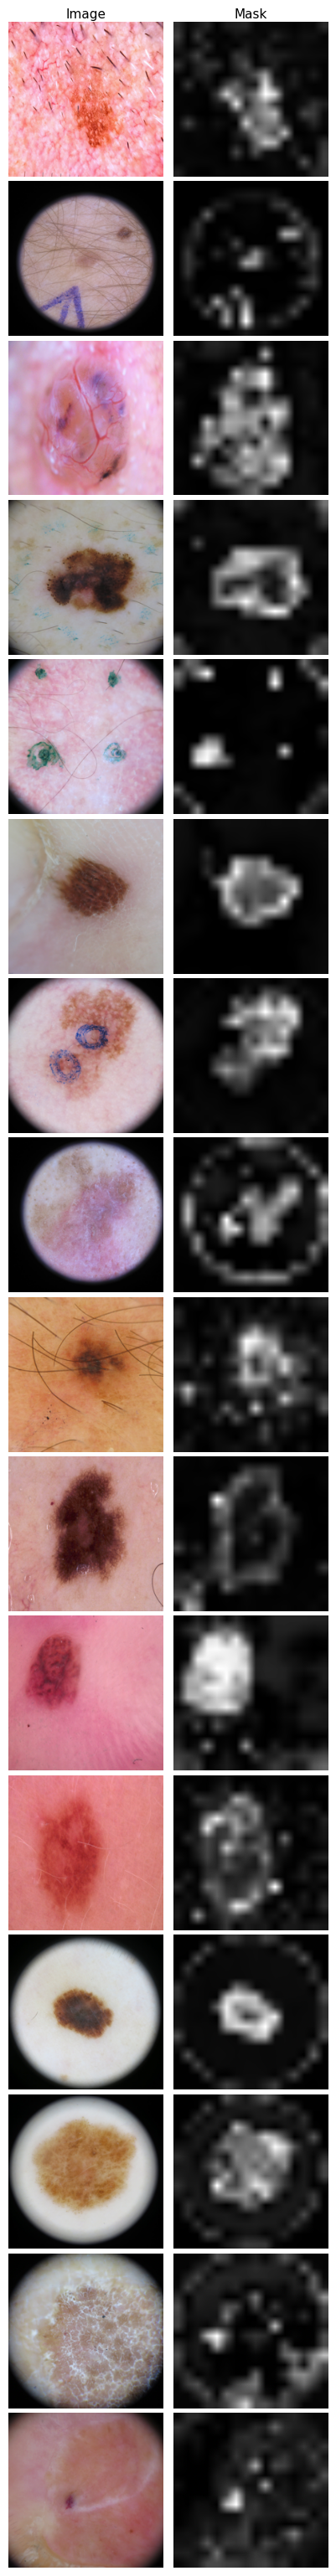

In [20]:
import matplotlib.pyplot as plt

n = 16

fig, axes = plt.subplots(
    n,
    2,
    figsize=(4, 2 * n),
    gridspec_kw={
        "wspace": 0.01,
        "hspace": 0.03
    }
)

for i in range(n):
    img = type_image[i].detach().permute(1, 2, 0).cpu()
    mask_img = mask[i, 0].detach().cpu()
    
    axes[i, 0].imshow(img)
    axes[i, 1].imshow(mask_img, cmap="gray")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

# Only one pair of headings
axes[0, 0].set_title("Image", fontsize=11, pad=3)
axes[0, 1].set_title("Mask", fontsize=11, pad=3)

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.96,
    bottom=0.01,
    wspace=0.01,
    hspace=0.03
)

plt.savefig(
    "../Figures_Saved/isic2019_dermos_Monet_clip_FT_attention.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.01
)

plt.show()

In [36]:
try: 
    flat_labels = torch.cat(labs2, dim = 0)
except:
    flat_labels = [label for batch in labs2 for label in batch]

oupt = torch.cat(oupt_list, dim = 0)
len(flat_labels)

16

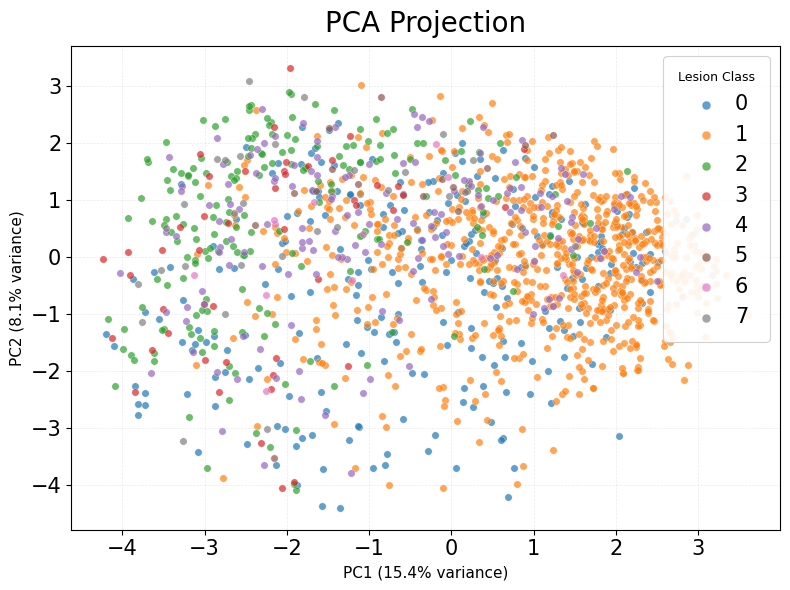

In [16]:
import numpy as np
plot_pca_clusters (oupt, flat_labels, name = '../Figures_Saved/Monet_isic2019_classes.svg')

In [33]:
from utils_external.metrics_platonic import AlignmentMetrics
# flat_labels = torch.stack(flat_labels, dim = 0)
one_hot_labels = F.one_hot(flat_labels.long(), num_classes=40)
print(AlignmentMetrics.svcca(oupt.float(), one_hot_labels.float(), 5)) # or  flat_labels = one_hot.float() 
# alternative svcca metrics https://github.com/google/svcca/blob/master/cca_core.py


0.26543023019780165


In [15]:
# code for pca plot
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
def plot_pca_clusters(x: torch.Tensor, labels, name = None):
    """
    Args:
        x:      (n, d) — feature vectors
        labels: one of:
                  - (n, c) tensor  — one-hot encoded
                  - (n,)   tensor  — integer class indices
                  - list of str    — class name per point e.g. ["cat", "dog", ...]
    """
    assert x.shape[0] == len(labels), "x and labels must have same number of points"
    # Normalize all label formats → list of strings
    if isinstance(labels, torch.Tensor):
        if labels.dim() == 2:                          # one-hot
            class_names = labels.argmax(dim=1).cpu().tolist()
        else:                                          # integer indices
            class_names = labels.cpu().tolist()
        class_names = [str(c) for c in class_names]
    elif isinstance(labels, list):                     # string names
        class_names = [str(c) for c in labels]
    else:
        raise ValueError(f"Unsupported labels type: {type(labels)}")
    unique_classes = sorted(set(class_names), key=lambda c: (int(c) if c.isdigit() else c))
    # unique_classes= ['0', '2', '3', '8', '6', '7', '9']
    # PCA to 2D
    pca = PCA(n_components=2)
    x_2d = pca.fit_transform(x.detach().cpu().numpy())  # (n, 2)
    # Plot
    # fig, ax = plt.subplots(figsize=(8, 6))
    # for cls in unique_classes:
    #     mask = [i for i, c in enumerate(class_names) if c == cls]
    #     ax.scatter(x_2d[mask, 0], x_2d[mask, 1], label=cls, alpha=0.6, s=20)
    # ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
    # ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
    # ax.set_title("PCA projection")
    # ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    # plt.tight_layout()
    # plt.show()
    fig, ax = plt.subplots(figsize=(8, 6))

    for cls in unique_classes:
        mask = np.array([c == cls for c in class_names])
    
        ax.scatter(
            x_2d[mask, 0],
            x_2d[mask, 1],
            label=cls,
            alpha=0.7,
            s=28,
            edgecolors="white",
            linewidths=0.3,
        )
    
    # Axis labels
    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)",
        fontsize=11
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)",
        fontsize=11
    )
    
    ax.set_title("PCA Projection", fontsize=20, pad=10)
    
    # Cleaner legend inside the plot
    legend = ax.legend(
        title="Lesion Class",
        loc="upper right",
        fontsize=15,
        title_fontsize=9,
        frameon=True,
        framealpha=0.9,
        borderpad=0.7,
        labelspacing=0.5,
        handletextpad=0.4,
        markerscale=1.2,
    )
    legend.get_frame().set_linewidth(0.8)
    # Subtle grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.25)
    ax.tick_params(axis="both", labelsize=15)
    plt.tight_layout()
    # Save publication-quality vector figure
    if name is not None:
        plt.savefig(
            name,
            format="svg",
            bbox_inches="tight",
        )
    
    plt.show()

In [35]:
# gromov hyperbolicity test
def delta_hyp_torch(dismat):
    p = 0
    row = dismat[p, :][None, :]
    col = dismat[:, p][:, None]
    XY_p = 0.5 * (row + col - dismat)
    maxmin = torch.minimum(XY_p[:, :, None], XY_p[None, :, :]).max(1).values
    return (maxmin - XY_p).max()
import numpy as np

idx = np.random.choice(len(oupt[keep]), 900)
all_features_small = image_feats_h[keep][idx]
# dists = distance_matrix(all_features_small, all_features_small)
dists = torch.cdist(all_features_small, all_features_small)
delta = delta_hyp_torch(dists)
diam = torch.max(dists)
del_rel =  2*delta/diam
print('delta relative: ', del_rel)
c = (0.144 / del_rel) ** 2
print('c value: ', c)

delta relative:  tensor(0.2328, device='cuda:0')
c value:  tensor(0.3826, device='cuda:0')
